# Ejercicio de normalizacion

![ITQ.png](attachment:9064aae4-1065-463b-a0a0-af732ab521be.png)

**Normalizacion**: Convertir los datos de entrada en un rango de 0 y 1, a este proceso lo llamamos homotecia

**Formula**

$x normalizado = (x - x mínimo ) / (x máximo - x mínimo )$

**Nombre**:Elian Suarez

**Fecha**: 4/11/2026

**Link**: <a href="https://github.com/Elits0/Fundamentos_Machine_Learning_26-27">Link repositorio</a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
import zipfile
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

In [ ]:
import os
os.environ['KAGGLE_CONFIG_DIR']="C:/uSERS/ADMIN-ITQ/.kaggle"

In [ ]:
os.makedirs("dataset", exist_ok=True)

In [ ]:
!kaggle datasets download -d uciml/iris

Dataset URL: https://www.kaggle.com/datasets/uciml/iris
License(s): CC0-1.0
100% 3.60k/3.60k [00:00<00:00, 8.13MB/s]



In [ ]:
with zipfile.ZipFile("iris.zip", 'r') as zip_ref:
    zip_ref.extractall("dataset")

In [ ]:
df = pd.read_csv("dataset/Iris.csv")

In [ ]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
if 'Id' in df.columns:
    df = df.drop(columns=["Id"])

In [ ]:
df.info()

df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:
X=df.drop(columns=['Species'])
y=df['Species']

In [ ]:
X.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


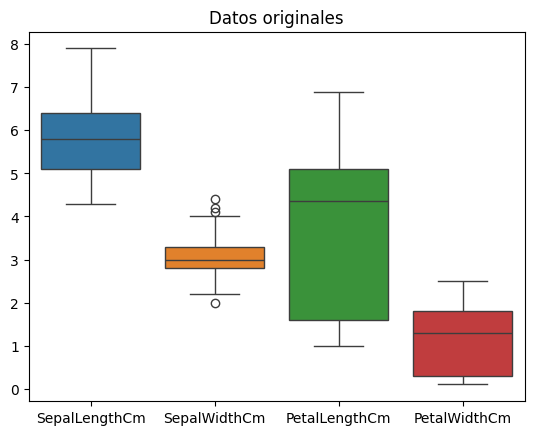

In [ ]:
sns.boxplot(data=X)

plt.title("Datos originales")
plt.show()

In [ ]:
normalizer = preprocessing.MinMaxScaler()
X_norm=normalizer.fit_transform(X)
X_norm = pd.DataFrame(X_norm, columns=X.columns)
X_norm.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0.222222,0.625000,0.067797,0.041667
1,0.166667,0.416667,0.067797,0.041667
2,0.111111,0.500000,0.050847,0.041667
3,0.083333,0.458333,0.084746,0.041667
4,0.194444,0.666667,0.067797,0.041667


In [ ]:
X_norm.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,0.428704,0.439167,0.467571,0.457778
std,0.230018,0.180664,0.299054,0.317984
min,0.000000,0.000000,0.000000,0.000000
25%,0.222222,0.333333,0.101695,0.083333
50%,0.416667,0.416667,0.567797,0.500000
75%,0.583333,0.541667,0.694915,0.708333
max,1.000000,1.000000,1.000000,1.000000


In [ ]:
standarizer = preprocessing.StandardScaler()
X_std=standarizer.fit_transform(X)
X_std= pd.DataFrame(X_std, columns=X.columns)
X_std.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,-0.900681,1.032057,-1.341272,-1.312977
1,-1.143017,-0.124958,-1.341272,-1.312977
2,-1.385353,0.337848,-1.398138,-1.312977
3,-1.506521,0.106445,-1.284407,-1.312977
4,-1.021849,1.263460,-1.341272,-1.312977


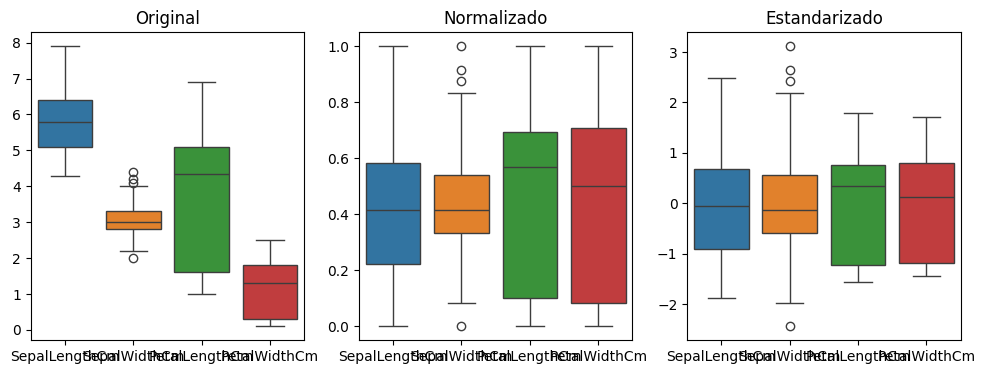

In [ ]:
plt.figure(figsize=(12,4))
3
plt.subplot(1,3,1)
sns.boxplot(data=X)
plt.title("Original")
plt.subplot(1,3,2)
sns.boxplot(data=X_norm)
plt.title("Normalizado")
plt.subplot(1,3,3)
sns.boxplot(data=X_std)
plt.title("Estandarizado")
plt.show()